In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from zipfile import ZipFile
from pathlib import Path

In [3]:
with ZipFile(r"C:\Users\ADMIN\Downloads\cats_and_dogs_filtered.zip") as z:
    z.extractall("animal_data")

In [4]:
train_path = next(Path("animal_data").rglob("train"))

val_path = train_path.parent / "validation"

print("Training:", train_path)
print("Validation:", val_path)

Training: animal_data\cats_and_dogs_filtered\train
Validation: animal_data\cats_and_dogs_filtered\validation


In [8]:
train_ds = keras.utils.image_dataset_from_directory(
    train_path,
    image_size=(160, 160),
    batch_size=32,
    label_mode="binary"
)
class_names = train_ds.class_names


Found 2000 files belonging to 2 classes.


In [9]:
val_ds = keras.utils.image_dataset_from_directory(
    val_path,
    image_size=(160, 160),
    batch_size=32,
    label_mode="binary",
    class_names=class_names
)

Found 1000 files belonging to 2 classes.


In [10]:
base_model = keras.applications.MobileNetV2(
    input_shape=(160, 160, 3),
    include_top=False,
    weights="imagenet"
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [11]:
model = keras.Sequential([
    keras.Input(shape=(160, 160, 3)),

    layers.Rescaling(1.0 / 127.5, offset=-1),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dense(1, activation="sigmoid")
])

In [12]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 2,225,153 (8.49 MB)

 Non-trainable params: 34,112 (133.25 KB)

In [13]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [14]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5


c:\Users\ADMIN\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


63/63 ━━━━━━━━━━━━━━━━━━━━ 200s 2s/step - accuracy: 0.9125 - loss: 0.2377 - val_accuracy: 0.7610 - val_loss: 3.2957
Epoch 2/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 156s 2s/step - accuracy: 0.9575 - loss: 0.1152 - val_accuracy: 0.7980 - val_loss: 3.7682
Epoch 3/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 149s 2s/step - accuracy: 0.9725 - loss: 0.0892 - val_accuracy: 0.8530 - val_loss: 2.0258
Epoch 4/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 148s 2s/step - accuracy: 0.9650 - loss: 0.0981 - val_accuracy: 0.5280 - val_loss: 10.9358
Epoch 5/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 190s 3s/step - accuracy: 0.9695 - loss: 0.0897 - val_accuracy: 0.5820 - val_loss: 9.5724


In [16]:
loss, accuracy = model.evaluate(val_ds)

print("Validation Accuracy:", round(accuracy * 100, 2), "%")

32/32 ━━━━━━━━━━━━━━━━━━━━ 12s 358ms/step - accuracy: 0.5820 - loss: 9.5724
Validation Accuracy: 58.2 %


In [17]:
images, labels = next(iter(val_ds))
prediction = model.predict(images[:1], verbose=0)
predicted = class_names[int(prediction[0][0] >= 0.5)]
actual = class_names[int(labels[0].numpy().item())]
print("Predicted:", predicted)
print("Actual:", actual)

Predicted: dogs
Actual: dogs


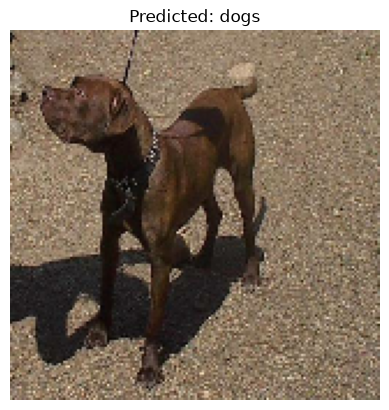

In [18]:
plt.imshow(images[0].numpy().astype("uint8"))
plt.title("Predicted: " + predicted)
plt.axis("off")
plt.show()

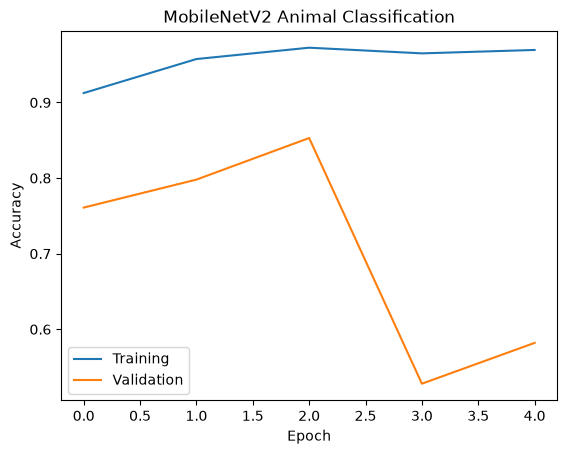

In [19]:
plt.plot(history.history["accuracy"], label="Training")

plt.plot(history.history["val_accuracy"], label="Validation")

plt.title("MobileNetV2 Animal Classification")

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.legend()

plt.show()